# Exploring other data generating functions

In this code we explore more complex functions, as compared to the centered parabola used in the files before this one (```first_experiments.ipynb``` and ```noise_structure.ipynb```). 

In [1]:
print('mare')

mare


In [2]:
%run ../base.ipynb

mare


## Sine

### data exploration
we start from a sine with $m = 5$ crossings of the $x$ axis in $(0, 10)$, a value chosen heuristically, to see how the noise acts on the data for a function that changes sign more often than the centered parabola.

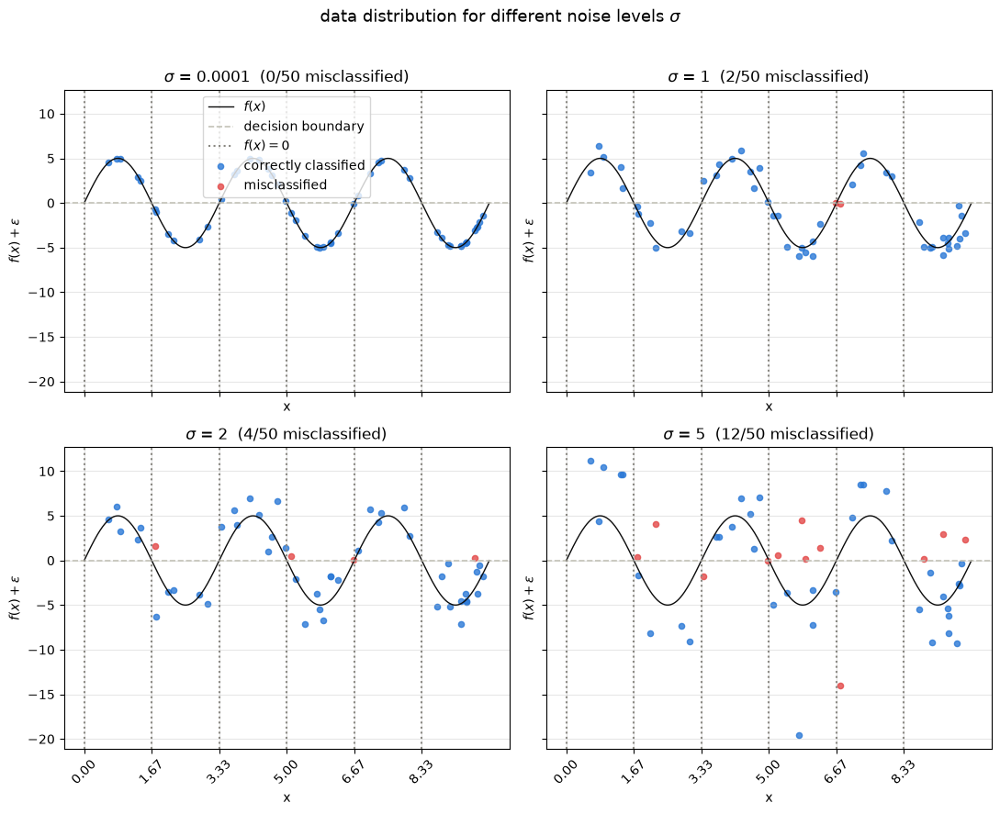

In [3]:
# sine() takes an extra m argument, but every place that uses
# f (sample_y, sample_y_bernoulli, explore_data, main_loop,
# animate_learned_function) calls it as a plain 1-argument f(x) — same
# contract centered_parabola already satisfies. so instead of threading
# m through all of those, bind it once with functools.partial
# (same trick already used for MLPClassifier's fixed hyperparameters below),
# and pass the resulting 1-argument callable everywhere f is expected.
from functools import partial

# NUMBER OF CROSSINGS of the x axis 
'''
Remark: num_crossings (hence m) is naively the number of crossings I want to see in the open interval (0, 10), hence if I want all points to the left of 5 being positive and all those to the right of 5 being negative I should set m = 1!
'''
num_crossings = 5
myfun = partial(sine, m=num_crossings)

# explore data distribution for this new f
explore_data(f=myfun, n=50, N=10_000, sigmas=(10**(-4), 1, 2, 5))

### explore a number of frequencies $(2, 10, 100, 1\_000, 10\_000)$






In [4]:
# DEFAULT PARAMETERS, shared by all the experiments below
# MODEL
mymodel = DecisionTreeClassifier

# PARAMETERS
supp_size = 10_000
data_size_test = 200_000
data_size_tr = 50
# a bit lower than the sigma = 5 used for the parabola: the sine has amplitude 5,
# so it spends more of the domain close to f = 0 and the same sigma flips more labels
noise_std = 3
num_iter = 100

def run_sine(num_crossings, bound_name="unionbound"):
    """
    explore data, train vs test error plots and animated learned function
    for the sine with num_crossings crossings, with the default parameters
    """
    myfun = partial(sine, m=num_crossings)

    # explore data distribution for this new f
    explore_data(f=myfun, n=data_size_tr, N=supp_size, sigmas=(10**(-4), 1, noise_std, 5))

    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=myfun, sigma=noise_std)

    # build models and do plots
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, f=myfun, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr,
          sigma=noise_std, T=num_iter, model=mymodel, bound_name=bound_name, bound_params={})

    # show animated function
    animation = animate_learned_function(model=mymodel, n=data_size_tr, best_pred=predictions,
                                         best_x=x, best_y=y, x_grid=x_grid, f=myfun)
    display(HTML(animation.to_jshtml()))

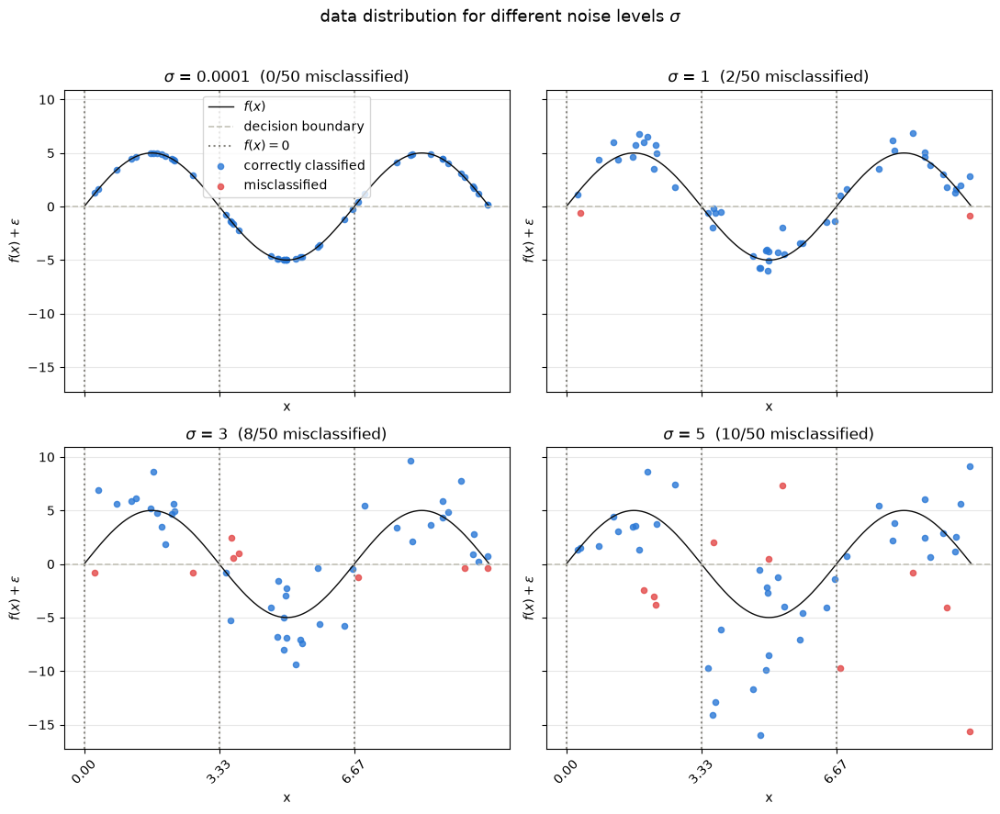

[checkpoint] bound: "unionbound" -> union_bound, params: []


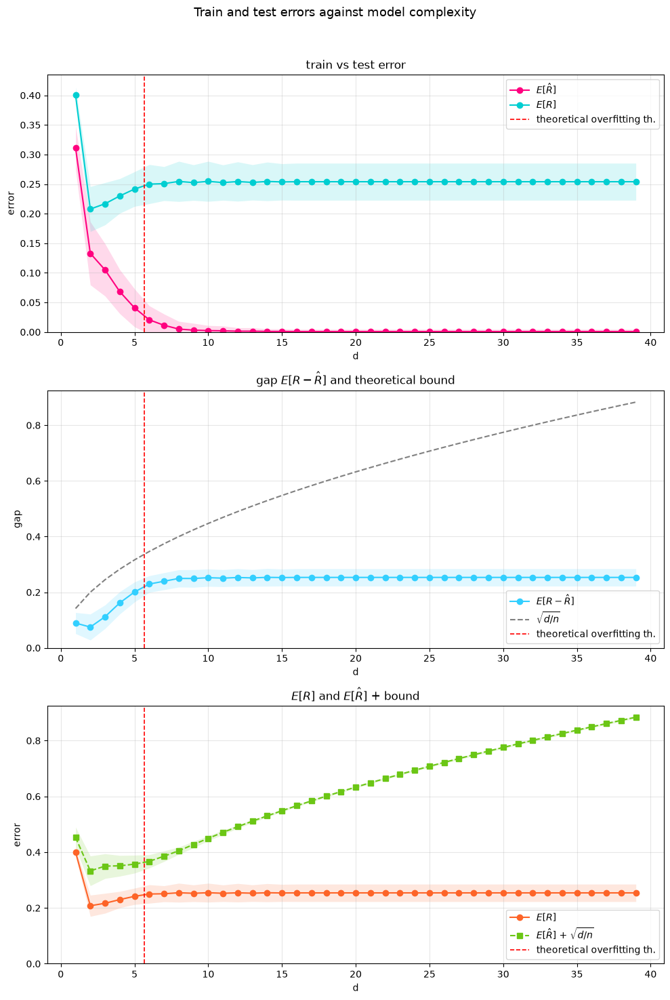

In [5]:
# m = 2
run_sine(num_crossings=2)

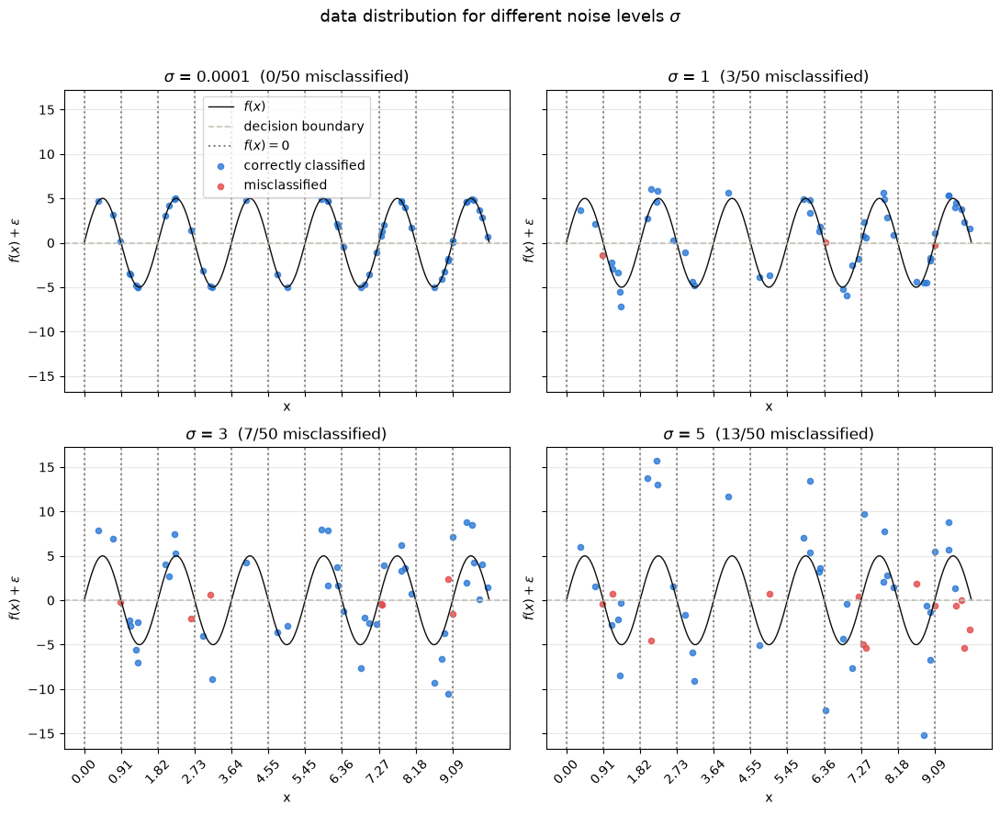

[checkpoint] bound: "unionbound" -> union_bound, params: []


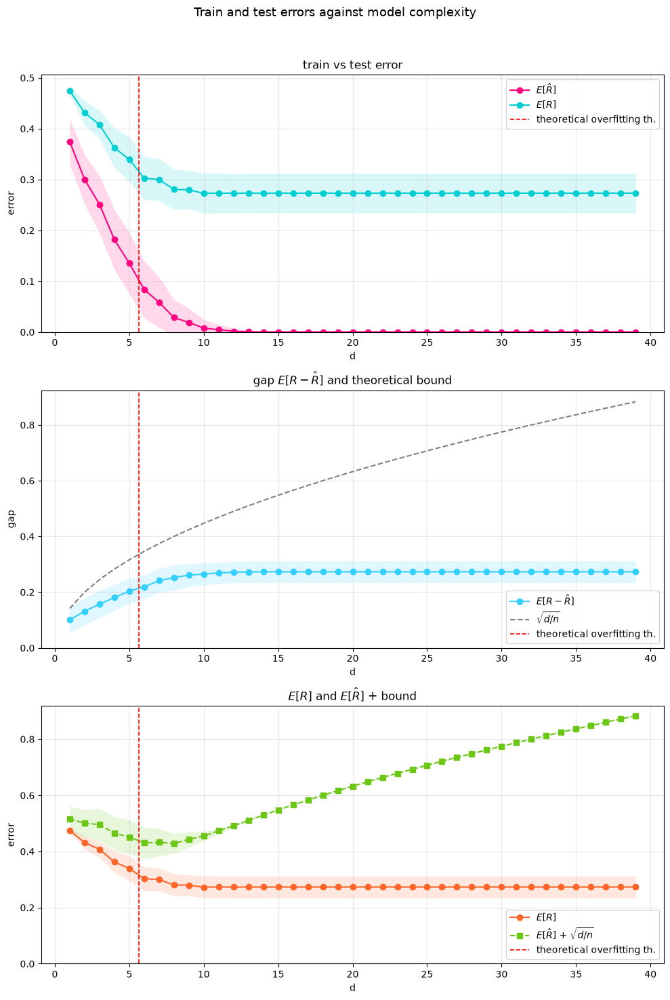

In [6]:
# m = 10
run_sine(num_crossings=10)

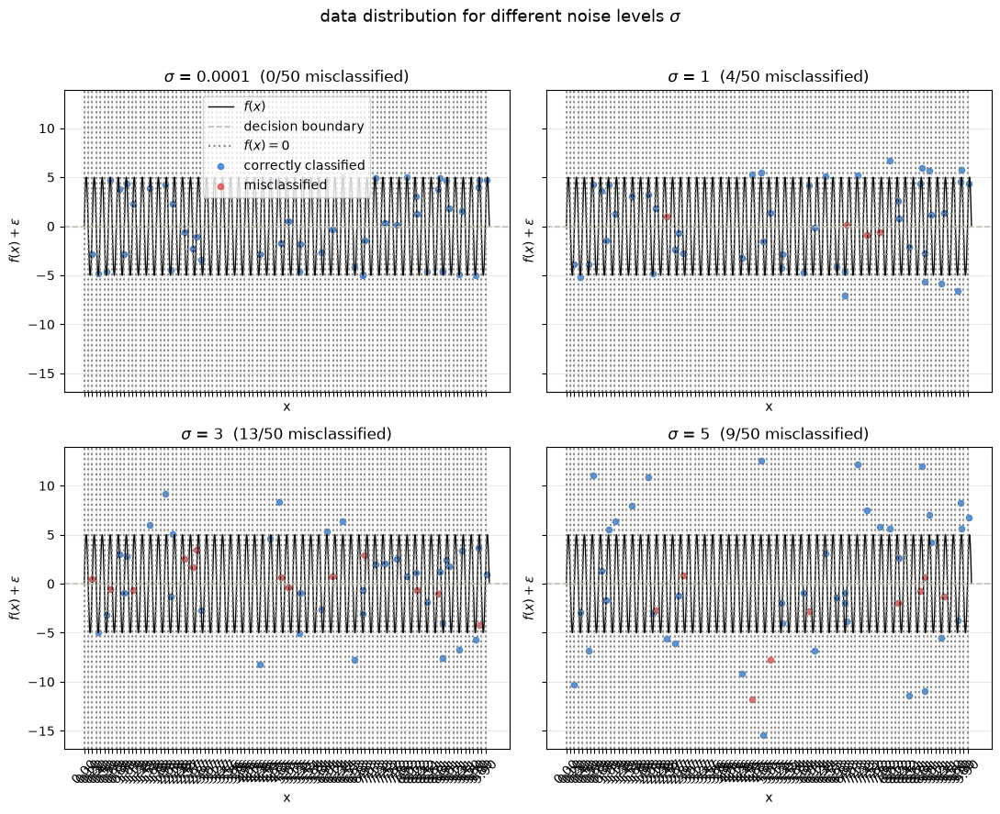

[checkpoint] bound: "unionbound" -> union_bound, params: []


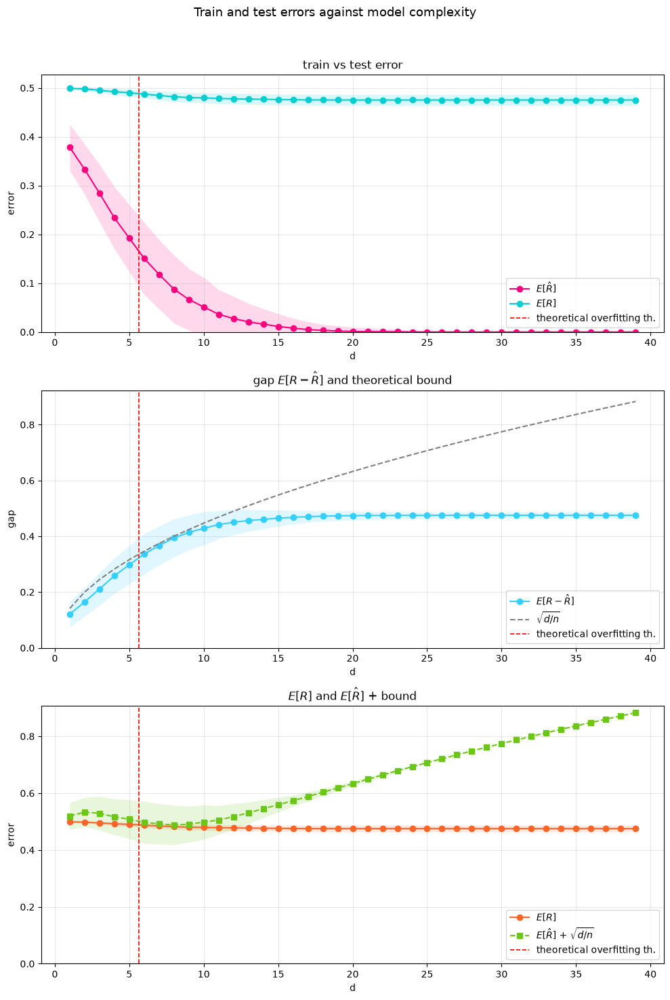

In [7]:
# m = 100
run_sine(num_crossings=100)

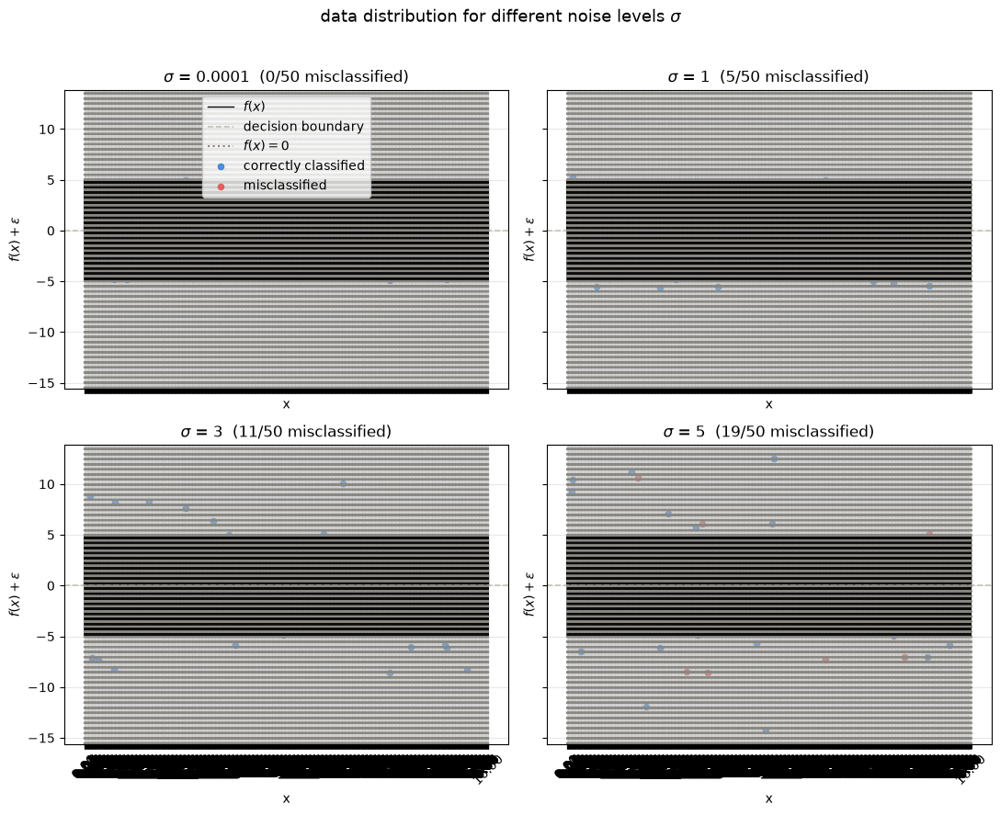

[checkpoint] bound: "unionbound" -> union_bound, params: []


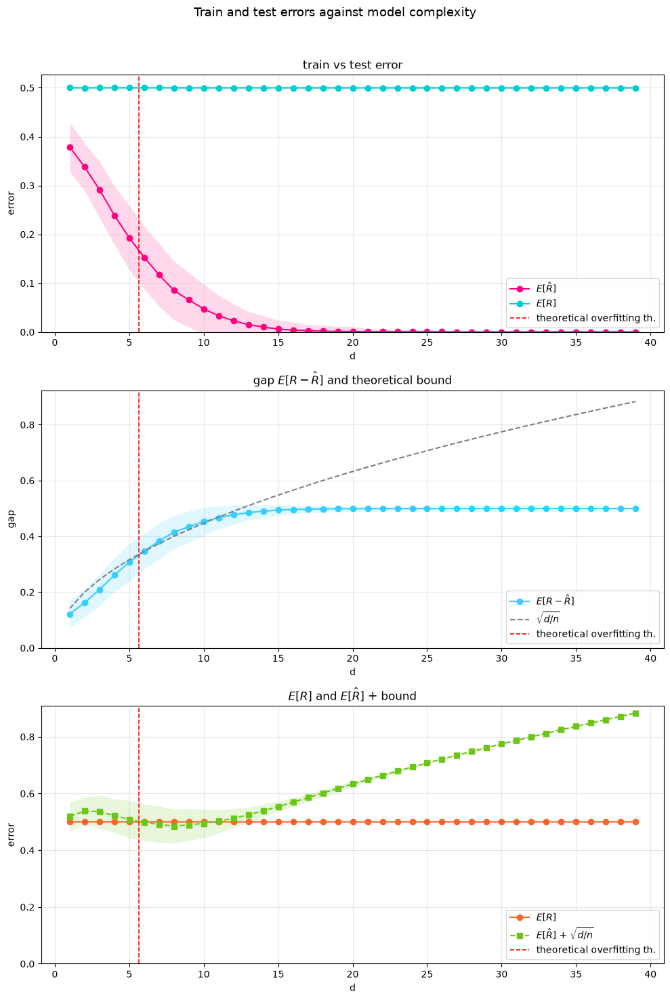

In [8]:
# m = 1_000
run_sine(num_crossings=1_000)

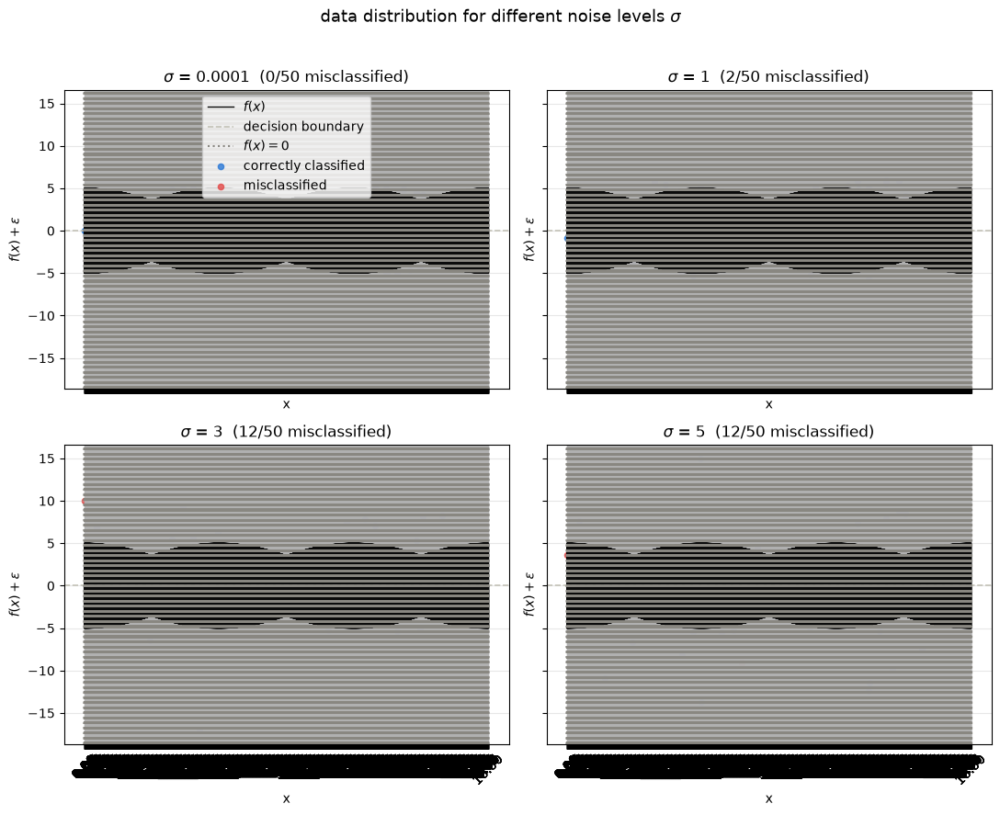

[checkpoint] bound: "unionbound" -> union_bound, params: []


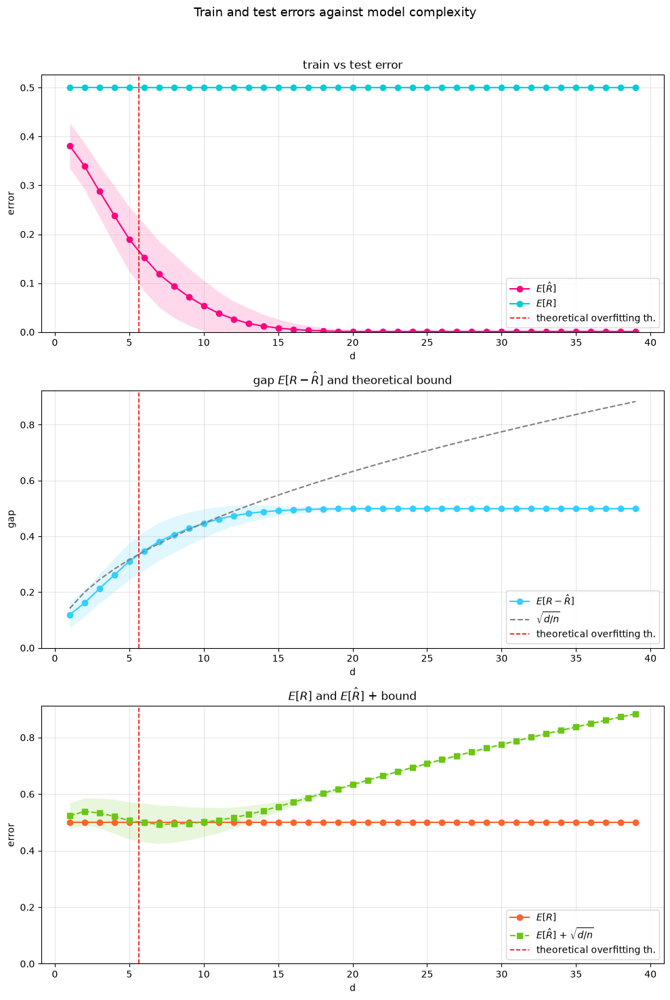

In [9]:
# m = 10_000
run_sine(num_crossings=10_000)

### per quale rapporto tra il numero di sign changes e num di training points ho test error = $0.5$? 



spoiler: con $n = 50$ e $\sigma = 3$, per $r \ge 10$ il test error è $0.5$ a ogni profondità, e già per $r = 5$ ($250$ crossings) resta sopra $0.49$. sotto scende lentamente ($\approx 0.48$ per $r = 2$, $\approx 0.43$ per $r = 1$). prendiamo quindi $r_c \approx 5$.

[checkpoint] bound: "unionbound" -> union_bound, params: []


[checkpoint] bound: "unionbound" -> union_bound, params: []


[checkpoint] bound: "unionbound" -> union_bound, params: []


[checkpoint] bound: "unionbound" -> union_bound, params: []


[checkpoint] bound: "unionbound" -> union_bound, params: []


[checkpoint] bound: "unionbound" -> union_bound, params: []


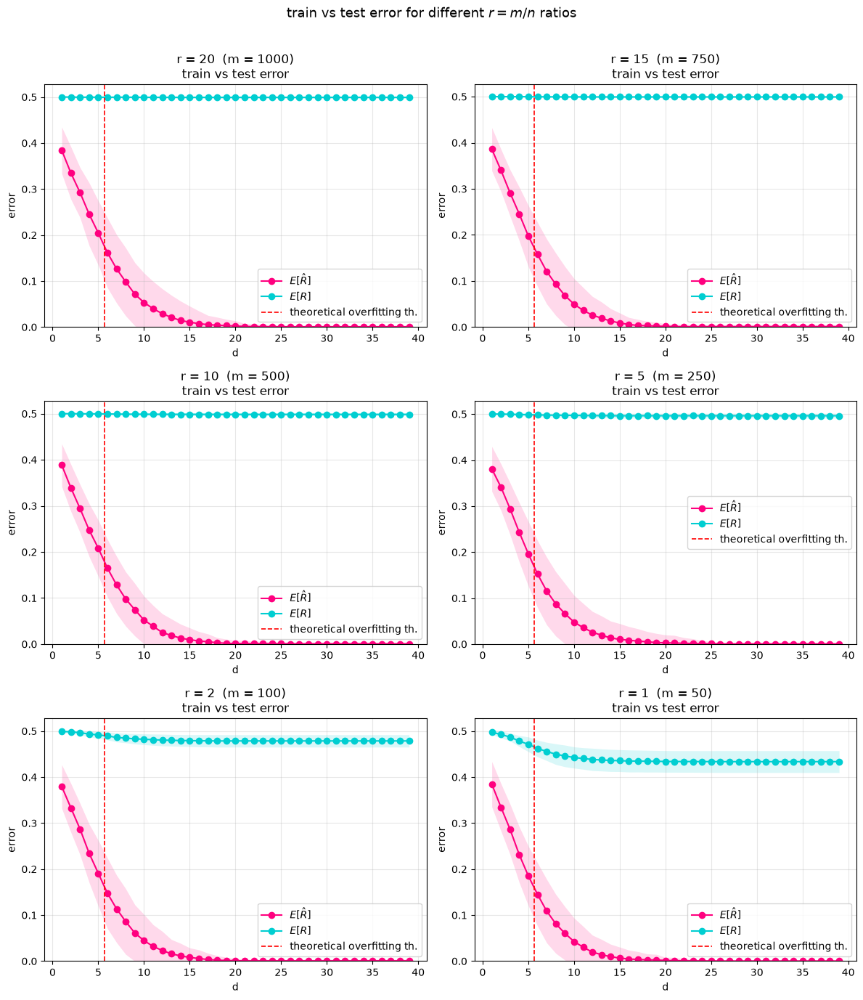

In [10]:
# find r_c: fix the ratio r = m/n (number of sine crossings over number of
# training points) and look for the threshold r_c above which the test error
# saturates at 0.5 (as good as guessing). sweep a handful of values
# and compare the train/test error plots side by side.
ratios = [20, 15, 10, 5, 2, 1]

# MODEL and PARAMETERS: the defaults set above

fig, axs = plt.subplots(3, 2, figsize=(12, 14))
fig.suptitle(r'train vs test error for different $r = m/n$ ratios', fontsize=13)

for ax, r in zip(axs.flat, ratios):
    num_crossings = round(r * data_size_tr)
    myfun = partial(sine, m=num_crossings)

    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=myfun, sigma=noise_std)

    # build models and do plots (only the train vs test error plot)
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, *_ = main_loop(x_test, y_test, n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, f=myfun, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, bound_name = "unionbound", bound_params = {}, two=False, three=False, axes=[ax])
    ax.set_title(f'r = {r}  (m = {num_crossings})\ntrain vs test error')

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

[checkpoint] bound: "unionbound" -> union_bound, params: []


[checkpoint] bound: "unionbound" -> union_bound, params: []


[checkpoint] bound: "unionbound" -> union_bound, params: []


[checkpoint] bound: "unionbound" -> union_bound, params: []


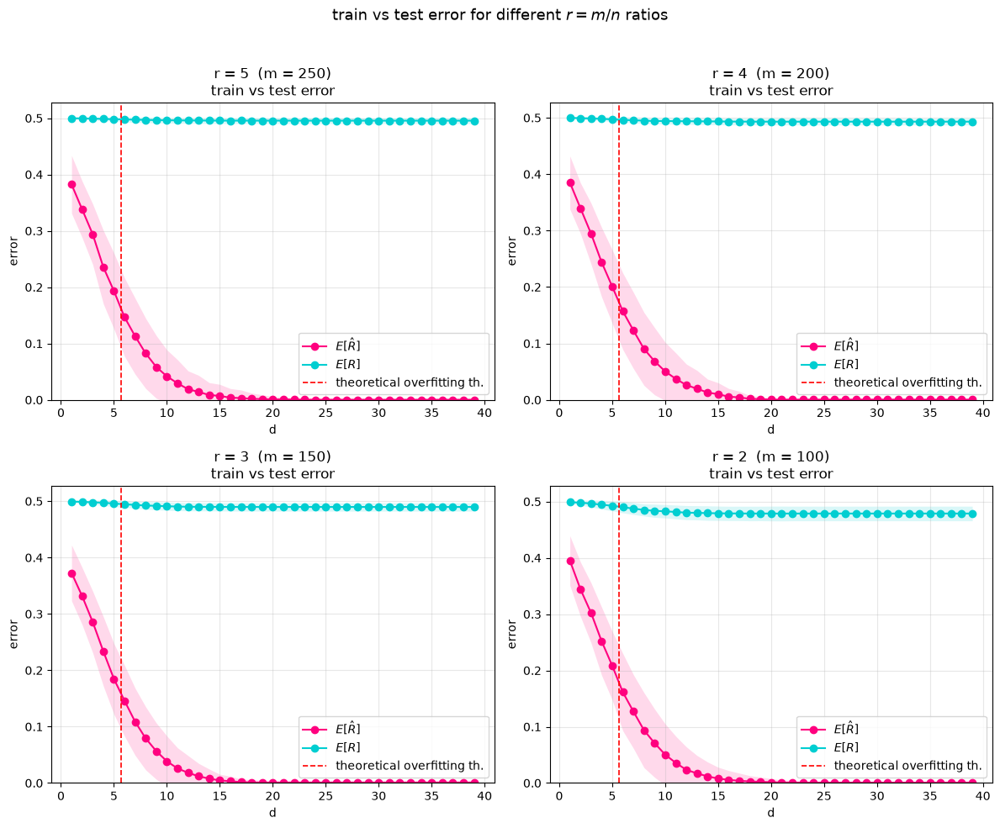

In [11]:
# same sweep as above, narrowing down to integer ratios.
ratios = [5, 4, 3, 2]

# MODEL and PARAMETERS: the defaults set above

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle(r'train vs test error for different $r = m/n$ ratios', fontsize=13)

for ax, r in zip(axs.flat, ratios):
    num_crossings = round(r * data_size_tr)
    myfun = partial(sine, m=num_crossings)

    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=myfun, sigma=noise_std)

    # build models and do plots (only the train vs test error plot)
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, *_ = main_loop(x_test, y_test, n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, f=myfun, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, bound_name = "unionbound", bound_params = {}, two=False, three=False, axes=[ax])
    ax.set_title(f'r = {r}  (m = {num_crossings})\ntrain vs test error')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### misclassified inputs: does $\sigma^*$ of the parabola still match $p = 0.8$?
in `noise_structure.ipynb` abbiamo calibrato $\sigma^*$ in modo che, per la parabola, il rumore gaussiano dia la stessa porzione di misclassified inputs di un errore bernoulliano con $p = 0.8$. verifichiamo se lo stesso $\sigma^*$ va bene anche per il seno, con $m = 10$ crossings (scelto euristicamente), facendo la media su $100$ campioni di training di size $n$.

gaussian,  sigma* (parabola) = 5.5: 0.294 ± 0.064 misclassified
bernoulli, p = 0.8:                 0.198 ± 0.058 misclassified


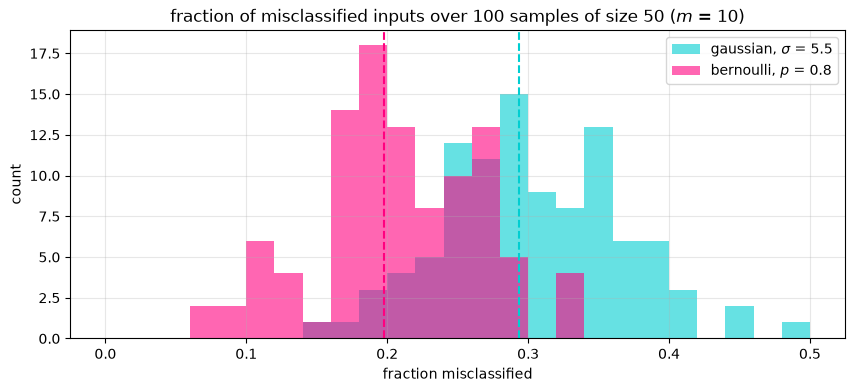

In [12]:
# NUMBER OF CROSSINGS of the x axis 
num_crossings = 10
myfun = partial(sine, m=num_crossings)

# PARAMETERS (on top of the defaults)
prob = 0.8
num_samples = 100

# sigma* calibrated on the parabola, as in noise_structure.ipynb
sigma_parabola = 5.5

# fraction of labels that disagree with the noiseless sign(f(x)), for each sample
frac_gauss = []; frac_bern = []
for _ in range(num_samples):
    x = sample_x(data_size_tr, supp_size)
    true_y = np.where(myfun(x) >= 0, 1, -1)
    frac_gauss.append(np.mean(sample_y(x, myfun, sigma=sigma_parabola) != true_y))
    frac_bern.append(np.mean(sample_y_bernoulli(x, myfun, p=prob) != true_y))

print(f'gaussian,  sigma* (parabola) = {sigma_parabola}: {np.mean(frac_gauss):.3f} ± {np.std(frac_gauss):.3f} misclassified')
print(f'bernoulli, p = {prob}:{" " * 17}{np.mean(frac_bern):.3f} ± {np.std(frac_bern):.3f} misclassified')

# distribution over the samples of the fraction misclassified, for the two noise structures
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 0.5, 26)
ax.hist(frac_gauss, bins=bins, color='#00CED1', alpha=0.6, label=rf'gaussian, $\sigma$ = {sigma_parabola}')
ax.hist(frac_bern,  bins=bins, color='#FF007F', alpha=0.6, label=rf'bernoulli, $p$ = {prob}')
ax.axvline(np.mean(frac_gauss), color='#00CED1', linestyle='--', linewidth=1.5)
ax.axvline(np.mean(frac_bern),  color='#FF007F', linestyle='--', linewidth=1.5)
ax.set_title(f'fraction of misclassified inputs over {num_samples} samples of size {data_size_tr} ($m$ = {num_crossings})')
ax.set_xlabel('fraction misclassified'); ax.set_ylabel('count')
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

non vale: il $\sigma^* = 5.5$ della parabola, sul seno, dà circa il $29\%$ di misclassified inputs, contro il $20\%$ di $p = 0.8$. il seno passa più tempo vicino a $0$ rispetto alla parabola, quindi lo stesso $\sigma$ flippa più label: i valori trovati per la parabola non valgono, e dobbiamo ricalibrare $\sigma^*$ sul seno.

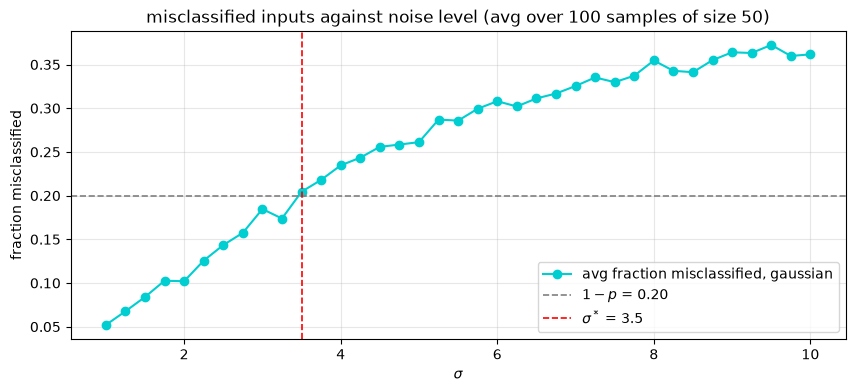

sigma* (sine) = 3.5


In [13]:
# recalibrate sigma* on the sine
sigma_star = find_sigma_star(f=myfun, p=prob, n=data_size_tr, N=supp_size, num_samples=num_samples)
print(f'sigma* (sine) = {sigma_star}')

il valore corretto per il seno è $\sigma^* = 3.5$, che usiamo da qui in poi.

### funzione semplice la imparo con pochi punti di data

qui verifichiamo il claim che per una funzione che cambia segno due volte, quindi è ben definita da $3$ punti (se ben distribuiti), la impariamo facilmente con due split. in particolare cerchiamo la size $n$ del training set sufficiente per impararla a profondità $2$ e $3$, cioè per avere un test error medio entro `tol` dal Bayes risk.

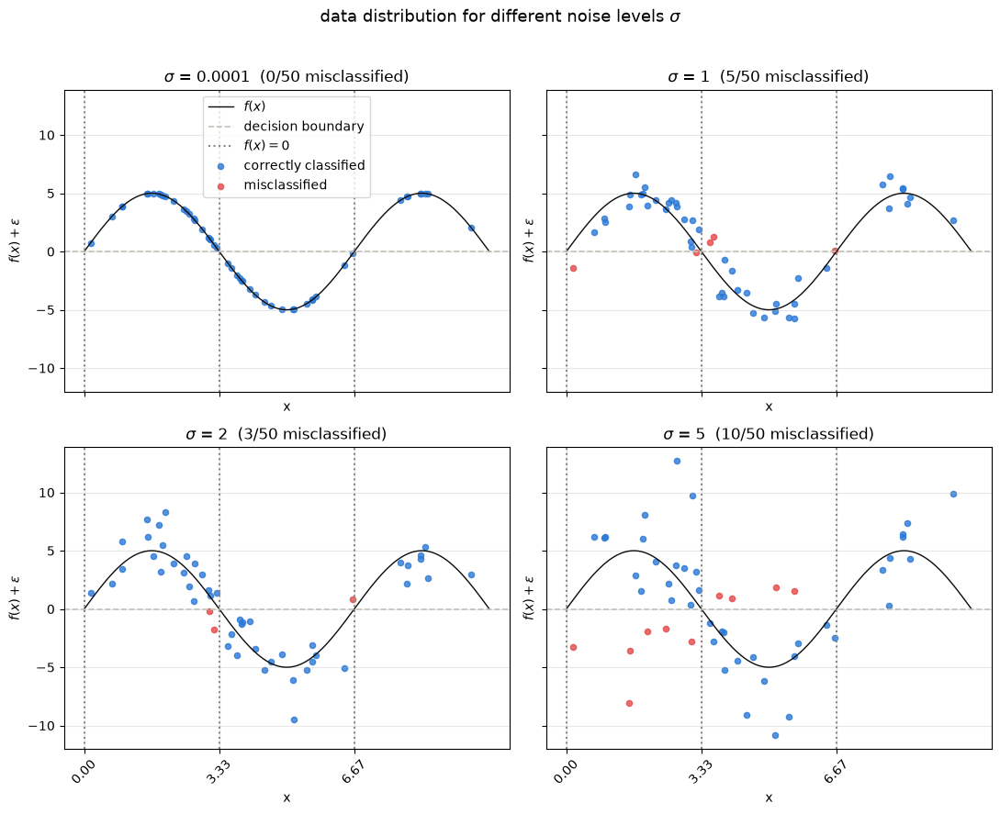

In [14]:
# NUMBER OF CROSSINGS of the x axis 
num_crossings = 2
myfun = partial(sine, m=num_crossings)

# explore data distribution for this new f
explore_data(f=myfun, n=data_size_tr, N=supp_size, sigmas=(10**(-4), 1, 2, 5))

Bayes risk: 0.202
depth 2: n = 1000 is sufficient
depth 3: n = 1000 is sufficient


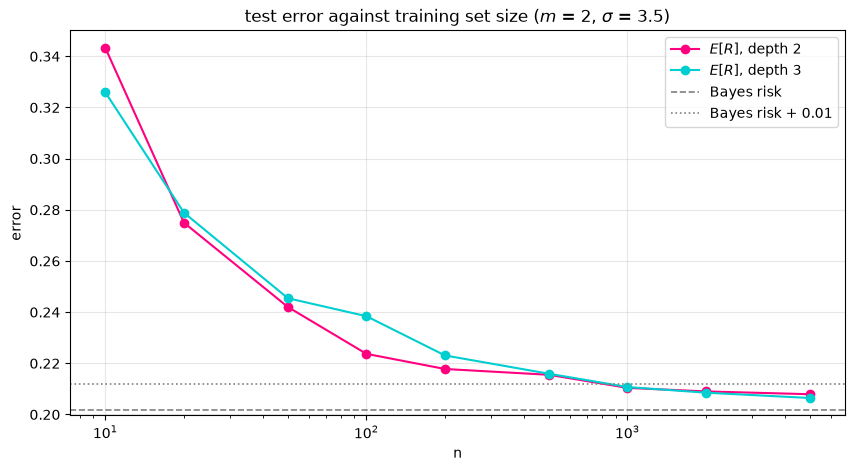

In [15]:
# noise calibrated on the sine above, from now on
noise_std = sigma_star

# PARAMETERS (on top of the defaults)
depths = [2, 3]
data_sizes = [10, 20, 50, 100, 200, 500, 1_000, 2_000, 5_000]
tol = 0.01

# build test set, and its Bayes risk (labels flipped by the noise w.r.t. sign(f(x)))
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y(x=x_test, f=myfun, sigma=noise_std)
bayes_risk = np.mean(y_test != np.where(myfun(x_test) >= 0, 1, -1))

# E[R] for each depth and training set size, averaged over num_iter training sets
E_Rs = {d: [] for d in depths}
for n in data_sizes:
    Rs = {d: [] for d in depths}
    for _ in range(num_iter):
        x = sample_x(n, supp_size)
        y = sample_y(x, myfun, sigma=noise_std)
        for d in depths:
            clf = mymodel(max_depth=d, random_state=42).fit(x.reshape(-1, 1), y)
            Rs[d].append(1 - clf.score(x_test.reshape(-1, 1), y_test))
    for d in depths:
        E_Rs[d].append(np.mean(Rs[d]))

# smallest n for which E[R] is within tol of the Bayes risk
n_sufficient = {d: next((n for n, e in zip(data_sizes, E_Rs[d]) if e - bayes_risk <= tol), None) for d in depths}
print(f'Bayes risk: {bayes_risk:.3f}')
for d in depths:
    print(f'depth {d}: n = {n_sufficient[d]} is sufficient')

fig, ax = plt.subplots(figsize=(10, 5))
for d, color in zip(depths, ['#FF007F', '#00CED1']):
    ax.plot(data_sizes, E_Rs[d], color=color, marker='o', label=rf'$E[R]$, depth {d}')
ax.axhline(bayes_risk, color='gray', linestyle='--', linewidth=1.2, label='Bayes risk')
ax.axhline(bayes_risk + tol, color='gray', linestyle=':', linewidth=1.2, label=f'Bayes risk + {tol}')
ax.set_xscale('log')
ax.set_title(rf'test error against training set size ($m$ = {num_crossings}, $\sigma$ = {noise_std})')
ax.set_xlabel('n'); ax.set_ylabel('error')
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

[checkpoint] bound: "unionbound" -> union_bound, params: []


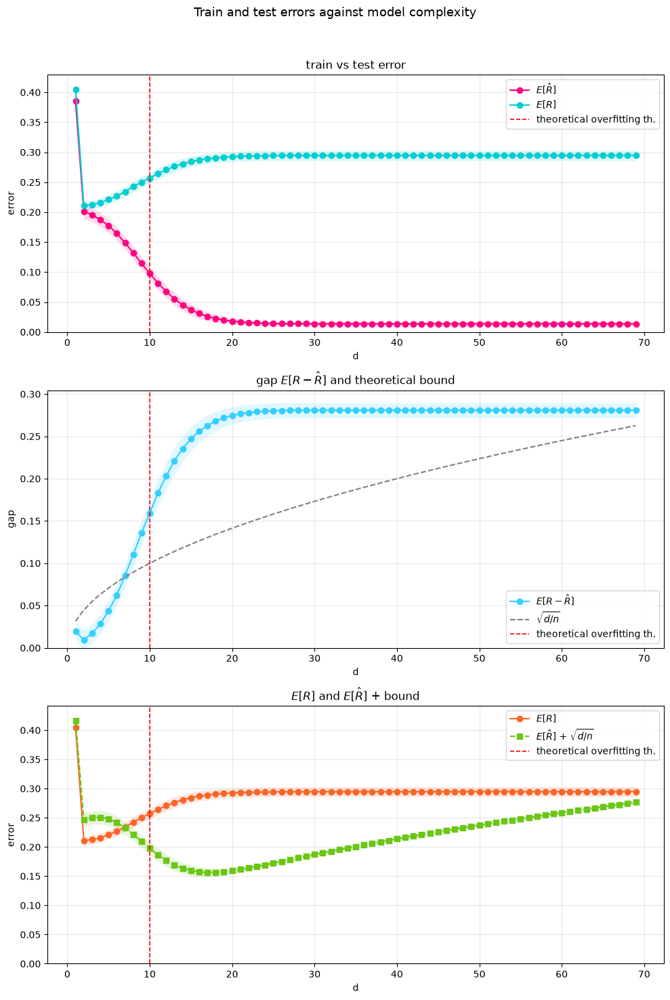

In [16]:
# train vs test error and learned function at the size sufficient for depth 2
data_size_tr_simple = n_sufficient[2]

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(x_test, y_test, n=data_size_tr_simple, sigma=noise_std, T=num_iter, model=mymodel, f=myfun, N=supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr_simple, sigma=noise_std, T=num_iter, model=mymodel, bound_name = "unionbound", bound_params={})

animation = animate_learned_function(model = mymodel, n = data_size_tr_simple, best_pred = predictions,
                         best_x = x, best_y = y, x_grid = x_grid, f = myfun)
HTML(animation.to_jshtml())

con $\sigma^* = 3.5$ il Bayes risk è $\approx 0.20$: sia a profondità $2$ che a profondità $3$ serve $n \approx 1\,000$ per arrivare entro $0.01$ dal Bayes risk. due split bastano a rappresentare la funzione, ma con questo rumore servono tanti punti per piazzarli bene.